
# Post-processing: plot and analyze the results

In [107]:
import meshio
import numpy as np
import glob, os

import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.colors import LogNorm
from matplotlib import mathtext
import math
from scipy import stats 
from tkinter import Tcl

#Plot Setup
font = {'size':14}
plt.rc('font', **font)
plt.rc('font', family='serif')
plt.rc('text', usetex=False)

In [122]:
x

array([0.75, 0.5 ], dtype=float32)

In [123]:
y

array([0.55, 0.55], dtype=float32)

## Measure total Energy

In [135]:
# Import snapshots
snapshot_dir = ''
files = glob.glob(snapshot_dir + "particles-*-rank-0.vtu")
# Sort the snapshots according to Natural sort
files = Tcl().call('lsort', '-dict', files)

# Parameters
E_ini = 1.0
time_step_sim = 1e-3
snapshot_rate = 10
SUN_X = 0.5
SUN_Y = 0.55

# Initialize arrays
E_dif_all = np.zeros( len(files) )
x_all = np.zeros( len(files) )
y_all = np.zeros( len(files) )
t_all = np.zeros( len(files) )

for N_snapshot, file in enumerate(files, start=0):
    
    print("N_snapshot: ", N_snapshot)
    time = N_snapshot * snapshot_rate * time_step_sim
    t_all[N_snapshot] = time
    
    snapshot = files[N_snapshot]
    print('Reading snapshot: ' + snapshot )
    print("time of simulation = ", time)
    print("********************************************")

    mesh = meshio.read( snapshot )
    print(mesh.point_data_to_sets)
    print("********************************************")

    # Import Fields
    pos = mesh.point_data["x"]
    
#    # Filter out the sun by position
#    x_mask = np.greater_equal( x, 0 )
#    y_min = -1e-2
#    y_max = 1e-3
#    y_mask = np.less_equal(y, y_max)
#    y_mask = y_mask & np.greater_equal(y, y_min)
#    pos_mask = x_mask & y_mask
#    x_line = x[pos_mask]

    x = pos[:,0]
    y = pos[:,1]
    x_all[N_snapshot] = x[1]
    y_all[N_snapshot] = y[1]

    E_ini = 1.5622
    E_tot = mesh.point_data["energyTot"][:,0]
    E_tot = np.sum(E_tot)
    E_dif = (E_tot - E_ini)/E_ini
    E_dif_all[N_snapshot] = E_dif

    print("Measure energy conservation:")
    print("Initial E =", E_ini)
    print("Total E =  ", E_tot)
    print("Relative Energy difference = ", E_dif )
    print("********************************************")

print("Done reading all snapshots. Total= ", N_snapshot )

N_snapshot:  0
Reading snapshot: particles-0-rank-0.vtu
time of simulation =  0.0
********************************************
<bound method Mesh.point_data_to_sets of <meshio mesh object>
  Number of points: 2
  Number of cells:
    vertex: 2
  Point data: x, cut-off-radius, association, v, a, energyKin, energyPot, energyTot>
********************************************
Measure energy conservation:
Initial E = 1.5622
Total E =   1.5622
Relative Energy difference =  -3.186646994587536e-08
********************************************
N_snapshot:  1
Reading snapshot: particles-1-rank-0.vtu
time of simulation =  0.01
********************************************
<bound method Mesh.point_data_to_sets of <meshio mesh object>
  Number of points: 2
  Number of cells:
    vertex: 2
  Point data: x, cut-off-radius, association, v, a, energyKin, energyPot, energyTot>
********************************************
Measure energy conservation:
Initial E = 1.5622
Total E =   1.56081
Relative Energy di

<bound method Mesh.point_data_to_sets of <meshio mesh object>
  Number of points: 2
  Number of cells:
    vertex: 2
  Point data: x, cut-off-radius, association, v, a, energyKin, energyPot, energyTot>
********************************************
Measure energy conservation:
Initial E = 1.5622
Total E =   1.56219
Relative Energy difference =  -6.365479984678204e-06
********************************************
N_snapshot:  149
Reading snapshot: particles-149-rank-0.vtu
time of simulation =  1.49
********************************************
<bound method Mesh.point_data_to_sets of <meshio mesh object>
  Number of points: 2
  Number of cells:
    vertex: 2
  Point data: x, cut-off-radius, association, v, a, energyKin, energyPot, energyTot>
********************************************
Measure energy conservation:
Initial E = 1.5622
Total E =   1.56061
Relative Energy difference =  -0.0010177596188312118
********************************************
N_snapshot:  150
Reading snapshot: particl

<bound method Mesh.point_data_to_sets of <meshio mesh object>
  Number of points: 2
  Number of cells:
    vertex: 2
  Point data: x, cut-off-radius, association, v, a, energyKin, energyPot, energyTot>
********************************************
Measure energy conservation:
Initial E = 1.5622
Total E =   1.4365
Relative Energy difference =  -0.08046347889517445
********************************************
N_snapshot:  284
Reading snapshot: particles-284-rank-0.vtu
time of simulation =  2.84
********************************************
<bound method Mesh.point_data_to_sets of <meshio mesh object>
  Number of points: 2
  Number of cells:
    vertex: 2
  Point data: x, cut-off-radius, association, v, a, energyKin, energyPot, energyTot>
********************************************
Measure energy conservation:
Initial E = 1.5622
Total E =   1.44635
Relative Energy difference =  -0.07415825217836358
********************************************
N_snapshot:  285
Reading snapshot: particles-28

<bound method Mesh.point_data_to_sets of <meshio mesh object>
  Number of points: 2
  Number of cells:
    vertex: 2
  Point data: x, cut-off-radius, association, v, a, energyKin, energyPot, energyTot>
********************************************
Measure energy conservation:
Initial E = 1.5622
Total E =   1.53307
Relative Energy difference =  -0.018646800522614426
********************************************
N_snapshot:  403
Reading snapshot: particles-403-rank-0.vtu
time of simulation =  4.03
********************************************
<bound method Mesh.point_data_to_sets of <meshio mesh object>
  Number of points: 2
  Number of cells:
    vertex: 2
  Point data: x, cut-off-radius, association, v, a, energyKin, energyPot, energyTot>
********************************************
Measure energy conservation:
Initial E = 1.5622
Total E =   1.54327
Relative Energy difference =  -0.012117531766294463
********************************************
N_snapshot:  404
Reading snapshot: particles

<bound method Mesh.point_data_to_sets of <meshio mesh object>
  Number of points: 2
  Number of cells:
    vertex: 2
  Point data: x, cut-off-radius, association, v, a, energyKin, energyPot, energyTot>
********************************************
Measure energy conservation:
Initial E = 1.5622
Total E =   1.552
Relative Energy difference =  -0.006529224314193346
********************************************
N_snapshot:  516
Reading snapshot: particles-516-rank-0.vtu
time of simulation =  5.16
********************************************
<bound method Mesh.point_data_to_sets of <meshio mesh object>
  Number of points: 2
  Number of cells:
    vertex: 2
  Point data: x, cut-off-radius, association, v, a, energyKin, energyPot, energyTot>
********************************************
Measure energy conservation:
Initial E = 1.5622
Total E =   1.55798
Relative Energy difference =  -0.0027013561848015654
********************************************
N_snapshot:  517
Reading snapshot: particles-

<bound method Mesh.point_data_to_sets of <meshio mesh object>
  Number of points: 2
  Number of cells:
    vertex: 2
  Point data: x, cut-off-radius, association, v, a, energyKin, energyPot, energyTot>
********************************************
Measure energy conservation:
Initial E = 1.5622
Total E =   1.56152
Relative Energy difference =  -0.0004352961012655266
********************************************
N_snapshot:  629
Reading snapshot: particles-629-rank-0.vtu
time of simulation =  6.29
********************************************
<bound method Mesh.point_data_to_sets of <meshio mesh object>
  Number of points: 2
  Number of cells:
    vertex: 2
  Point data: x, cut-off-radius, association, v, a, energyKin, energyPot, energyTot>
********************************************
Measure energy conservation:
Initial E = 1.5622
Total E =   1.56207
Relative Energy difference =  -8.320823672365959e-05
********************************************
N_snapshot:  630
Reading snapshot: particl

... (6 outputs left out)

<bound method Mesh.point_data_to_sets of <meshio mesh object>
  Number of points: 2
  Number of cells:
    vertex: 2
  Point data: x, cut-off-radius, association, v, a, energyKin, energyPot, energyTot>
********************************************
Measure energy conservation:
Initial E = 1.5622
Total E =   1.41098
Relative Energy difference =  -0.0967993943216004
********************************************
N_snapshot:  1537
Reading snapshot: particles-1537-rank-0.vtu
time of simulation =  15.370000000000001
********************************************
<bound method Mesh.point_data_to_sets of <meshio mesh object>
  Number of points: 2
  Number of cells:
    vertex: 2
  Point data: x, cut-off-radius, association, v, a, energyKin, energyPot, energyTot>
********************************************
Measure energy conservation:
Initial E = 1.5622
Total E =   1.41399
Relative Energy difference =  -0.09487260225838363
********************************************
N_snapshot:  1538
Reading snaps

Total E =   1.49609
Relative Energy difference =  -0.042318490262435095
********************************************
N_snapshot:  1673
Reading snapshot: particles-1673-rank-0.vtu
time of simulation =  16.73
********************************************
<bound method Mesh.point_data_to_sets of <meshio mesh object>
  Number of points: 2
  Number of cells:
    vertex: 2
  Point data: x, cut-off-radius, association, v, a, energyKin, energyPot, energyTot>
********************************************
Measure energy conservation:
Initial E = 1.5622
Total E =   1.48301
Relative Energy difference =  -0.050691298403121546
********************************************
N_snapshot:  1674
Reading snapshot: particles-1674-rank-0.vtu
time of simulation =  16.740000000000002
********************************************
<bound method Mesh.point_data_to_sets of <meshio mesh object>
  Number of points: 2
  Number of cells:
    vertex: 2
  Point data: x, cut-off-radius, association, v, a, energyKin, energyPo

N_snapshot:  1803
Reading snapshot: particles-1803-rank-0.vtu
time of simulation =  18.03
********************************************
<bound method Mesh.point_data_to_sets of <meshio mesh object>
  Number of points: 2
  Number of cells:
    vertex: 2
  Point data: x, cut-off-radius, association, v, a, energyKin, energyPot, energyTot>
********************************************
Measure energy conservation:
Initial E = 1.5622
Total E =   1.47852
Relative Energy difference =  -0.05356546169266845
********************************************
N_snapshot:  1804
Reading snapshot: particles-1804-rank-0.vtu
time of simulation =  18.04
********************************************
<bound method Mesh.point_data_to_sets of <meshio mesh object>
  Number of points: 2
  Number of cells:
    vertex: 2
  Point data: x, cut-off-radius, association, v, a, energyKin, energyPot, energyTot>
********************************************
Measure energy conservation:
Initial E = 1.5622
Total E =   1.49152
Rela

<bound method Mesh.point_data_to_sets of <meshio mesh object>
  Number of points: 2
  Number of cells:
    vertex: 2
  Point data: x, cut-off-radius, association, v, a, energyKin, energyPot, energyTot>
********************************************
Measure energy conservation:
Initial E = 1.5622
Total E =   1.56057
Relative Energy difference =  -0.001043399307276393
********************************************
N_snapshot:  1923
Reading snapshot: particles-1923-rank-0.vtu
time of simulation =  19.23
********************************************
<bound method Mesh.point_data_to_sets of <meshio mesh object>
  Number of points: 2
  Number of cells:
    vertex: 2
  Point data: x, cut-off-radius, association, v, a, energyKin, energyPot, energyTot>
********************************************
Measure energy conservation:
Initial E = 1.5622
Total E =   1.56219
Relative Energy difference =  -6.365479984678204e-06
********************************************
N_snapshot:  1924
Reading snapshot: part

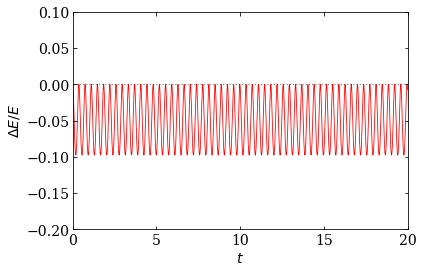

In [147]:
# Plot radial profiles
fig = plt.figure(figsize=(6, 4)) 
gs = gridspec.GridSpec(1,1,) 

ax0 = plt.subplot(gs[0])
plt.plot(t_all, E_dif_all, c='r', lw=0.8, zorder=1)
plt.xlabel(r'$t$')
plt.ylabel(r'$\Delta E/E$')
plt.margins(0.05, 0.1)
plt.tick_params(direction='in', top=True, right=True)
plt.axhline(0, c='gray', ls=':', lw=1.2,zorder=-49 )
plt.xlim(0, t_all.max())
plt.ylim(-0.2, 0.1 )


plt.show()
plt.close()

In [130]:
t_all[7]

0.07

In [133]:
t_all.max()

0.1